In [41]:
import pandas as pd
import numpy as np
import warnings
from astropy.io import fits
from astropy import modeling
from matplotlib import pyplot as plt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from astropy.constants import c
from astropy.modeling import models
from astropy import units as u
from specutils.spectra import Spectrum, SpectralRegion
from specutils.fitting import fit_lines, fit_generic_continuum
from specutils.analysis import equivalent_width
from specutils.fitting import find_lines_derivative
from astropy.stats import sigma_clip
from astropy.table import Table
import re
import os
from PyAstronomy import pyasl
from PyAstronomy.pyasl import fastRotBroad, rotBroad, specAirVacConvert, airtovac2, equidistantInterpolation
from scipy.interpolate import interp1d

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
})

# Functions

In [32]:
def get_spectral_order(folder_path, echelle_order, step=0.01):
    all_fluxes = []
    all_wavelengths = []
    # SN_list = []

    last_header = None

    for filename in os.listdir(folder_path):
        if filename.endswith(".fits"):
            file_path = os.path.join(folder_path, filename)

            with fits.open(file_path) as hdul:
                header = dict(hdul[12].header['*DVR\D+|*RV\D+|*CCFJDSUM*|ccfrvmod|'].items())
                header.update(dict(hdul[0].header['OBJECT*|*DATE-OBS|*SCI-OBJ|*QRA|*QDEC|OBSJD|*QSPT'].items()))
                header.update({'rv_correction':hdul[0].header[f'SSBRV{173 - echelle_order:03d}']})
                last_header = header

                SN = hdul[0].header['EXTSNR']
                activity = Table(hdul[13].data)

                c_kms = c.to('km/s').value  # Speed of light in km/s
                rv = header['CCFRVMOD'] - header['rv_correction'] #correcting from heliocentric rv
    
                wave = (hdul[7].data[echelle_order] * u.AA) / (1 + rv / c_kms)
                wave = wave.value

                flux = np.asarray(hdul[1].data[echelle_order], dtype=float)

                # Remove invalid pixels
                valid = (np.isfinite(wave) & np.isfinite(flux))

                wave = wave[valid]
                flux = flux[valid]

                # Make sure wavelength is sorted
                sort_idx = np.argsort(wave)

                wave = wave[sort_idx]
                flux = flux[sort_idx]

                all_wavelengths.append(wave)
                all_fluxes.append(flux)

    # ? Find wavelength range shared by ALL observations

    common_min = max(np.min(wave) for wave in all_wavelengths)

    common_max = min(np.max(wave) for wave in all_wavelengths)

    if common_min >= common_max:
        raise ValueError(f"No common wavelength range for order {echelle_order}")

    # Fixed common observed grid
    wavelengths = np.arange(
        common_min,
        common_max + step/2,
        step
    )

    # ? Interpolate every observation onto common grid
    resampled_fluxes = []

    for wave, flux in zip(all_wavelengths, all_fluxes):
        interp_flux = np.interp(wavelengths, wave, flux)
        resampled_fluxes.append(interp_flux)

    resampled_fluxes = np.asarray(resampled_fluxes)

    # Average observations
    flux = np.mean(resampled_fluxes, axis=0)

    return wavelengths, flux, last_header


def fit_spectrum(wavelengths, flux, poly_degree=10, n_iter=6, sigma=2.0):

    # --- Remove NaNs / Infs ---
    valid = np.isfinite(wavelengths) & np.isfinite(flux)
    lambda_valid = wavelengths[valid]
    flux_valid = flux[valid]

    # Optional: small offset if needed
    flux_valid = flux_valid + 10

    # --- Initial mask (start with everything) ---
    mask = np.ones(len(lambda_valid), dtype=bool)

    fit_g = modeling.fitting.LevMarLSQFitter()

    for _ in range(n_iter):

        # Fit polynomial to currently accepted pixels
        p_init = models.Polynomial1D(degree=poly_degree)
        continuum_fit = fit_g(p_init,
                              lambda_valid[mask],
                              flux_valid[mask])

        # Compute residuals
        model_flux = continuum_fit(lambda_valid)
        residuals = flux_valid - model_flux

        # Estimate scatter robustly
        std = np.std(residuals[mask])

        # Reject only absorption features (negative residuals)
        new_mask = residuals > -sigma * std

        # Stop if mask stops changing
        if np.all(new_mask == mask):
            break

        mask = new_mask

    # --- Final continuum ---
    continuum = continuum_fit(lambda_valid)

    # --- Normalize ---
    flux_norm = flux_valid / continuum

    return continuum_fit, lambda_valid, flux_valid, flux_norm



# def get_eqs(vacuum, lambda_valid, diff, div, window):
#     region = SpectralRegion((vacuum - window/2) * u.AA,(vacuum + window/2) * u.AA)
#     spectrum = Spectrum(spectral_axis=lambda_valid*u.AA, flux = (diff+1)*u.dimensionless_unscaled)
#     spectrum2 = Spectrum(spectral_axis=lambda_valid*u.AA, flux = (div)*u.dimensionless_unscaled)

#     ew = equivalent_width(spectrum, continuum = 1*u.dimensionless_unscaled, regions = region, mask_interpolation = None)
    
#     return ew

def get_eqs(vacuum, lambda_valid, diff, div, vsini,
            factor=1.5, min_velocity=10):

    c = 299792.458  # km/s

    half_width_velocity = max(factor * vsini, min_velocity)

    half_width_A = vacuum * half_width_velocity / c
    full_width_A = 2 * half_width_A

    print(f"Window = {full_width_A:.2f} Å")

    region = SpectralRegion(
        (vacuum - half_width_A) * u.AA,
        (vacuum + half_width_A) * u.AA
    )

    spectrum = Spectrum(
        spectral_axis=lambda_valid * u.AA,
        flux=(diff + 1) * u.dimensionless_unscaled
    )

    ew = equivalent_width(
        spectrum,
        continuum=1 * u.dimensionless_unscaled,
        regions=region,
        mask_interpolation=None
    )

    return ew, full_width_A


def get_rms(wave, flux, mod, vacuum, window):

    # Make sure all three arrays have the same shape
    if not (wave.shape == flux.shape == mod.shape):
        raise ValueError(
            f"Shape mismatch in get_rms(): "
            f"wave={wave.shape}, "
            f"flux={flux.shape}, "
            f"model={mod.shape}"
        )

    # Create wavelength mask
    if vacuum in [8500.35, 8544.44, 8664.52]:

        left_wing = ((wave > vacuum - 5) & (wave < vacuum - window/2))
        right_wing = ((wave > vacuum + window/2) & (wave < vacuum + 5))

        mask = left_wing | right_wing

    elif vacuum == 5855.32:

        mask = ((wave > 5858) & (wave < 5860))

    else:
        return np.nan

    # Apply the SAME mask to observed and model
    obs = flux[mask]
    model = mod[mask]

    # Make sure the masked arrays still match
    if obs.shape != model.shape:
        raise ValueError(
            f"Masked shape mismatch: "
            f"obs={obs.shape}, model={model.shape}"
        )

    if len(obs) == 0:
        return np.nan

    rms = np.sqrt(np.mean((obs - model)**2))

    return rms


def get_params(df, tic_id):

    # Default values for missing parameters
    default_logg = 4.5
    default_logg_err = 0.1
    default_MH = 0.0
    default_MH_err = 0.1

    # Special vsini value for TIC 437054608
    special_vsini = 9

    star = df[df["TIC"] == tic_id].iloc[0]

    teff = star["Teff_1"]
    teff_err = star["s_Teff"]

    logg = star["logg_1"]
    logg_err = star["s_logg"]

    MH = star["M_H"]
    MH_err = star["M_H_ERR"]

    vsini = star["VSINI"]

    # Replace NaN values with defaults
    if pd.isna(logg):
        logg = default_logg

    if pd.isna(logg_err):
        logg_err = default_logg_err

    if pd.isna(MH):
        MH = default_MH

    if pd.isna(MH_err):
        MH_err = default_MH_err

    # Override vsini for TIC 437054608
    if tic_id == 437054608:
        vsini = special_vsini

    return star, teff, teff_err, logg, logg_err, MH, MH_err, vsini


def get_activity_indicator(vacuum, ew):
    if vacuum == 8500.35:
        WIRT = ew.value
        log_WIRT = np.log10(abs(ew.value))
        log_RHK = (log_WIRT-3.49)/1.03
        RHK = 10**log_RHK
    elif vacuum == 8544.44:
        WIRT = ew.value
        log_WIRT = np.log10(abs(ew.value))
        log_RHK = (log_WIRT-5.19)/1.42
        RHK = 10**log_RHK
    elif vacuum == 8664.52:
        WIRT = ew.value
        log_WIRT = np.log10(abs(ew.value))
        log_RHK = (log_WIRT-6.00)/1.64
        RHK = 10**log_RHK
    else:
        return None
    return log_RHK, log_WIRT, WIRT, RHK


def get_errs(lambda_valid, flux_norm, broadened, vacuum, window, ew):
    center_mask = (lambda_valid > (vacuum - 0.05)) & (lambda_valid < (vacuum + 0.05))
    # center = np.interp(vacuum, lambda_valid, flux_norm)
    center = np.mean(flux_norm[center_mask])
    if vacuum == 8500.35 or vacuum == 8544.44:
        mask = (lambda_valid > (8555)) & (lambda_valid < (8570))
        mean = np.mean(flux_norm[mask])
        noise = np.std(flux_norm[mask])
        S_N = mean/noise
    elif vacuum == 8664.52:
        mask = (lambda_valid > (8640)) & (lambda_valid < (8655))
        mean = np.mean(flux_norm[mask])
        noise = np.std(flux_norm[mask])
        S_N = mean/noise
    stat_noise = (center*(1+center))/((S_N)**2)
    # WIRT_err = np.sqrt(1+(center/mean))*((window - ew.value)/S_N)

    return stat_noise, S_N, center


# def get_synth(model_file):
#     with fits.open(model_file) as hdul:
#         flux2 = hdul[0].data 
#         header = hdul[0].header

#         n = header["NAXIS1"]
#         crval = header["CRVAL1"]
#         cdelt = header["CDELT1"]
#         crpix = header["CRPIX1"]

#     wave2 = (crval + (np.arange(n) + 1 - crpix) * cdelt)*10
#     #air to vac
#     s = 10**4/wave2
#     n = 1 + 0.00008336624212083 + 0.02408926869968 / (130.1065924522 - s**2) + 0.0001599740894897 / (38.92568793293 - s**2)
#     wave2 = np.array(wave2 * n)
#     flux2 = np.array(flux2)
#     flux2 = np.interp(lambda_valid, wave2, flux2, left=1.0, right=1.0)

#     return wave2, flux2

def get_synth(model_file):

    with fits.open(model_file) as hdul:
        model_flux = np.asarray(hdul[0].data, dtype=float)

        header = hdul[0].header

        n = header["NAXIS1"]
        crval = header["CRVAL1"]
        cdelt = header["CDELT1"]
        crpix = header["CRPIX1"]

    # Create wavelength array and convert nm to Angstroms
    model_wave = (crval + (np.arange(n) + 1 - crpix) * cdelt) * 10.0

    # Convert air to vacuum
    s = 10**4 / model_wave

    refractive_index = (1 + 0.00008336624212083 + 0.02408926869968 / (130.1065924522 - s**2) + 0.0001599740894897 / (38.92568793293 - s**2))

    model_wave = model_wave * refractive_index

    # Make sure wavelength is sorted
    order = np.argsort(model_wave)

    model_wave = model_wave[order]
    model_flux = model_flux[order]

    return model_wave, model_flux


def parse_model_filename(model_file):

    filename = os.path.basename(model_file)

    pattern = (
        r"Teff(?P<teff>[-+]?\d+\.?\d*)"
        r"_logg(?P<logg>[-+]?\d+\.?\d*)"
        r"_MH(?P<mh>[-+]?\d+\.?\d*)"
        r"_vsini(?P<vsini>[-+]?\d+\.?\d*)"
    )

    match = re.search(pattern, filename)

    if match is None:
        return np.nan, np.nan, np.nan, np.nan

    return (
        float(match.group("teff")),
        float(match.group("logg")),
        float(match.group("mh")),
        float(match.group("vsini"))
    )


def interpolate_model_to_observed(model_wave, model_flux, observed_wave):
    # ? Interpolate synthetic spectrum onto the observed wavelength grid.

    # Only use the overlapping wavelength region
    valid = ((observed_wave >= model_wave.min()) & (observed_wave <= model_wave.max()))

    model_on_observed = np.full(observed_wave.shape, np.nan, dtype=float)

    model_on_observed[valid] = np.interp(observed_wave[valid], model_wave, model_flux)

    return model_on_observed, valid


def get_irt_window(vac, vsini, factor=1.5, min_velocity=10):
    """
    Calculate the full Ca II IRT window width in Angstroms
    from vsini in km/s.
    """
    c = 299792.458  # km/s

    half_width_velocity = max(factor * vsini, min_velocity)
    half_width_A = vac * half_width_velocity / c

    return 2 * half_width_A

<>:13: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:13: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
/var/folders/l4/_mvnx6k155979tth3g7sqpmr0000gn/T/ipykernel_73386/3322621625.py:13: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  header = dict(hdul[12].header['*DVR\D+|*RV\D+|*CCFJDSUM*|ccfrvmod|'].items())


# Inputs

In [35]:
'''Params'''

path = '/Users/brooklyngustaf/Desktop/Research/'
df = pd.read_csv(path + f'Brooklyn_NEID_spectra_project/GOLD_WD_binaries_forDon_APOGEE_GAIA_TIC_2MASS_StarHorse.csv')

# tic_id = [316316335]
tic_id = [
63939535,
316316335,
307786701,
168707425,
236017803,
333166853,
257304664,
202364425,
437054608,
16117219,
435238791,
9429166,
387424191,
136954576,
63082902,
344713506,
# 252791409,
321317174,
309663455,
39718658,
70666120,
291016095,
117249718,
250384503,
8200813,
67907704]

# windows = [4.0, 3.0, 2.5, 3.0, 1.5, 1.5, 3.0, 5.0, 1.0, 2.0, 1.0, 1.0, 0.5, 0.5, 0.5, 0.25,
#             # 0.5,
#             0.5, 5.0, 0.25, 0.25, 5.0,0.5, 1.0, 0.5, 0.75]

# Pipeline

In [42]:

for tic in tic_id:

    folder_path = path + f'Brooklyn_NEID_spectra_project/l2fits/TIC_{tic}'
    model_path = path + f'NEID_Activity/synthetic_models/TIC_{tic}'
    model_files = [
        os.path.join(model_path, f)
        for f in os.listdir(model_path)
        if f.endswith(".fits")
    ]

    star, teff, teff_err, logg, logg_err, MH, MH_err, vsini = get_params(df, tic)

    # * Orders: H-alpha (80), H-beta (47), Ca II H&K (18 and 17), Ca II Triplet (101 and 102)
    # *        Na I Doublet (69), H-Gamma (32)
    # * Vacuum Wavelengths: H-alpha (6564.614), H-beta (4862.721), Ca II H&K (3969.29, 3934.77), Ca II Triplet (8500.35, 8544.44, and 8664.52)
    # *                    Na I Doublet (5891.58, 5897.56), H-gamma (4340.46)

    '''Barium'''
    # echelle_order = [68]
    # vacuum = [5855.32]
    # labels = ['Ba II']

    '''Ca II IRT'''
    echelle_order = [101, 101, 102]
    vacuum = [8500.35, 8544.44, 8664.52]
    labels = ['Ca II IRT 1', 'Ca II IRT 2', 'Ca II IRT 3']

    '''H alpha'''
    # echelle_order = [80]
    # vacuum = [6564.614]
    # labels = ['H alpha']

    '''Everything'''
    # echelle_order = [17, 18, 32, 47, 68, 80, 101, 101, 102]
    # vacuum = [3934.77, 3969.29, 4341.68, 4862.721, 5855.32, 6564.614, 8500.35, 8544.44, 8664.52]
    # labels = ['CaII H', 'CaII K', 'H Gamma', 'H Beta', 'Ba II', 'H Alpha', 'CaII IRT 1', 'CaII IRT 2', 'CaII IRT 3']

    observed_data = {}

    for order, vac, label in zip(echelle_order, vacuum, labels):

        wavelengths, flux, header = get_spectral_order(folder_path, order, step=0.01)

        continuum_fit, lambda_valid, flux_valid, flux_norm = fit_spectrum(wavelengths, flux)

        observed_data[vac] = {
            "lambda": lambda_valid,
            "flux_norm": flux_norm,
            "order": order,
            "label": label
        }
    print("Observed data keys:", observed_data.keys())

    results = []

    for model_file in model_files:

        teff_model, logg_model, mh_model, vsini_model = \
            parse_model_filename(model_file)

        # Read synthetic spectrum on its native grid
        model_wave, model_flux = get_synth(model_file)

        total_rms = 0.0
        valid_rms = True

        for vac in vacuum:

            lambda_obs = observed_data[vac]["lambda"]
            flux_obs = observed_data[vac]["flux_norm"]

            # Interpolate model onto THIS observed grid
            flux_model, overlap_mask = \
                interpolate_model_to_observed(
                    model_wave,
                    model_flux,
                    lambda_obs
                )

            # Check that the arrays match
            if len(lambda_obs) != len(flux_model):
                raise ValueError(
                    f"Shape mismatch at {vac} Å: "
                    f"observed={len(lambda_obs)}, "
                    f"model={len(flux_model)}"
                )

            # Need enough model coverage
            if not np.any(overlap_mask):
                valid_rms = False
                break

            rns_window = get_irt_window(vac, vsini)

            rms = get_rms(
                lambda_obs,
                flux_obs,
                flux_model,
                vac,
                rns_window
            )

            if not np.isfinite(rms):
                valid_rms = False
                break

            total_rms += rms

        if valid_rms:

            results.append({
                "file": model_file,
                "Teff": teff_model,
                "logg": logg_model,
                "MH": mh_model,
                "vsini": vsini_model,
                "total_rms": total_rms
            })

    results_df = pd.DataFrame(results)

    if len(results_df) == 0:
        raise ValueError(
            f"No valid synthetic models could be compared "
            f"with TIC {tic}"
        )

    best = results_df.loc[
        results_df["total_rms"].idxmin()
    ]

    best_model = best["file"]
    vsini_best = best["vsini"]

    print(best)
    print(best_model)

    '''Plot Everything'''

    fig, axes = plt.subplots(2, len(echelle_order), figsize=(16, 10), gridspec_kw={'height_ratios': [3, 1]}, sharex='col', sharey='row', dpi=500, squeeze=False)
    # * gridspec_kw={'height_ratios': [3, 1]}

    # ew_list = []
    ew_list = []
    rms_values = []
    stat_noise_list = []
    alpha_list = []

    model_wave, model_flux = get_synth(best_model)

    for i, (order, vac, label) in enumerate(zip(echelle_order, vacuum, labels)):

        lambda_valid = observed_data[vac]["lambda"]
        flux_norm = observed_data[vac]["flux_norm"]

        # Model -> THIS observed wavelength grid
        flux_mod, overlap_mask = interpolate_model_to_observed(model_wave, model_flux, lambda_valid)

        # Keep only wavelengths where model exists
        lambda_valid = lambda_valid[overlap_mask]
        flux_norm = flux_norm[overlap_mask]
        flux_mod = flux_mod[overlap_mask]

        # Now these are guaranteed to have identical shape
        assert (lambda_valid.shape == flux_norm.shape == flux_mod.shape)

        diff = flux_norm - flux_mod
        div = (flux_norm/flux_mod)

        half_width_velocity = max(1.25 * vsini_best, 10)  # km/s
        half_width_A = vac * half_width_velocity / 299792.458

        lower = vac - half_width_A
        upper = vac + half_width_A

        mask = (lambda_valid >= lower) & (lambda_valid <= upper)

        print(f"Line center: {vac:.2f} Å")
        print(f"best vsini: {vsini_best}")
        print(f"EW region: {lower:.3f}–{upper:.3f} Å")
        print(f"Available wavelengths: {lambda_valid.min():.3f}–{lambda_valid.max():.3f} Å")
        print(f"Points inside EW region: {mask.sum()}")
        # ew = get_eqs(vac, lambda_valid, diff, div, window)
        ew, full_width_A = get_eqs(vac, lambda_valid, diff, div, vsini_best)
        ew_list.append(ew.value)

        rms = get_rms(lambda_valid, flux_norm, flux_mod, vac, full_width_A)
        rms_values.append(rms)

        log_RHK, log_WIRT, WIRT, RHK = get_activity_indicator(vac, ew)

        stat_noise, S_N, center = get_errs(lambda_valid, flux_norm, flux_mod, vac, full_width_A, ew)
        stat_noise_list.append(stat_noise)

        ax1 = axes[0, i]   # top row
        ax2 = axes[1, i]   # bottom row
        # ax3 = axes[2, i] 

        ax1.plot(lambda_valid, flux_norm, color='black')
        # ax1.plot(lambda_valid, broadened, color='red', label = f'BT-Settl')
        ax1.plot(lambda_valid, flux_mod, color='blue', label = f'SPECTRUM+MARCS+Grevesse2007+VALD')
        ax1.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
        ax1.axhline(1, color='darkgray', linewidth=1)
        ax1.axvline(vac - full_width_A/2, color='gray', linestyle='--', linewidth=0.6)
        ax1.axvline(vac + full_width_A/2, color='gray', linestyle='--', linewidth=0.6)
        ax1.set_xlim(vac - 5, vac + 5)
        ax1.set_ylim(0.2, 1.4)
        ax1.legend(fontsize=12)
        ax1.set_title(f'{labels[i]}')

        # window_mask = (lambda_valid > vac - window/2) & (lambda_valid < vac + window/2)
        window_mask = (lambda_valid > vac - full_width_A/2) & (lambda_valid < vac + full_width_A/2)

        # ax2.plot(lambda_valid, diff, color='red', label = f'rms = {rms:.3f}')
        ax2.plot(lambda_valid, diff, color='blue')
        ax2.axhline(0, color='darkgray', linewidth=1)
        ax2.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
        ax2.axvline(vac - full_width_A/2, color='gray', linestyle='--', linewidth=0.6)
        ax2.axvline(vac + full_width_A/2, color='gray', linestyle='--', linewidth=0.6)
        # ax2.fill_between(lambda_valid[window_mask], diff[window_mask], 0, label=fr"ew = {ew.value:.3f} $\AA$", color = 'lightpink')
        ax2.fill_between(lambda_valid[window_mask], diff[window_mask], 0, label=fr"ew = {ew.value:.3f} $\AA$", color = 'lightskyblue')
        ax2.set_xlim(vac - 5, vac + 5)
        ax2.set_ylim(-0.2, 1.2)
        ax2.legend(fontsize=12)

        # ax3.plot(lambda_valid, diff2, color='blue', label = f'rms2 = {rms2:.3f}')
        # ax3.axhline(0, color='darkgray', linewidth=1)
        # ax3.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
        # ax3.fill_between(lambda_valid[window_mask], diff2[window_mask], 0, label=fr"ew2 = {ew2.value:.3f} $\AA$", color = 'lightskyblue')
        # ax3.set_xlim(vac - 5, vac + 5)
        # ax3.set_ylim(-0.2, 1.2)
        # ax3.legend(fontsize=12)

    w = np.array([0.5, 1.0, 0.5])

    ew_array = np.array(ew_list)
    stat_noise_array = np.array(stat_noise_list)

    WIRT_total = np.sum(np.abs(ew_array)) ########## take out abs and add negative to ew calculation
    log_WIRT_total = np.log10(WIRT_total)

    log_RHK_total = (log_WIRT_total - 5.09)/1.29
    RHK_total = 10**log_RHK_total
    WIRT_err_total = np.sqrt((full_width_A**2)*(np.sum((w**2)*(stat_noise_array))))
    log_WIRT_err = WIRT_err_total / (WIRT_total * np.log(10))
    log_RHK_err = log_WIRT_err / 1.29
    RHK_err = np.log(10) * RHK_total * log_RHK_err



    fig.suptitle(fr"Star: {header['OBJECT']}  $T_{{eff}} = {teff} \pm {teff_err}$ K  $\log g = {logg} \pm {logg_err}$  [M/H] = {MH}  $v\sin i = {vsini}$ km/s" 
        "\n" fr"Model: $T_{{eff}} = {best['Teff']}$  $\log g = {best['logg']}$  $v\sin i = {vsini_best}$ km/s  [M/H] = {best['MH']}"
        "\n" fr"$\log \Delta W_{{IRT}} = {log_WIRT_total:.4f} \pm {log_WIRT_err:.4f}$  $\log R'_{{HK}} = {log_RHK_total:.4f} \pm {log_RHK_err:.4f}$",
        fontsize=20)

    for ax in axes[1, :]:
        ax.set_xlabel("Wavelength (Å)", fontsize=16)
        axes[0, 0].set_ylabel("Normalized Flux", fontsize=16)
        # axes[1, 0].set_ylabel("Residual Flux", fontsize=16)
        # axes[2, 0].set_ylabel("Residual Flux", fontsize=16)

    for ax in axes.flatten():
        ax.minorticks_on()

        ax.tick_params(
            axis='both',
            which='major',
            direction='in', 
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=8,
            width=1
        )

        ax.tick_params(
            axis='both',
            which='minor',
            direction='in',      
            top=True,
            right=True,
            bottom=True,
            left=True,
            length=4,
            width=0.8
        )

        ax.spines['top'].set_visible(True)
        ax.spines['right'].set_visible(True)

    plt.tight_layout()
    plt.show()

    print(f"log_WIRT_total = {log_WIRT_total:.4f} Å  log_RHK_total = {log_RHK_total:.4f}\nlog_WIRT_err = {log_WIRT_err:.4f}  log_HK_err = {log_RHK_err:.4f}\nWIRT_total = {WIRT_total:.4f}  RHK_total = {RHK_total:.6f}\nWIRT_err = {WIRT_err_total:.4f}  RHK_err = {RHK_err:.6f}")


Observed data keys: dict_keys([8500.35, 8544.44, 8664.52])
file         /Users/brooklyngustaf/Desktop/Research/NEID_Ac...
Teff                                                    4413.0
logg                                                       4.6
MH                                                       -0.08
vsini                                                     35.9
total_rms                                             0.231048
Name: 54, dtype: object
/Users/brooklyngustaf/Desktop/Research/NEID_Activity/synthetic_models/TIC_63939535/TIC_63939535_Teff4413_logg4.6_MH-0.08_vsini35.9_843.1_871.5.fits
Line center: 8500.35 Å
best vsini: 35.9
EW region: 8499.078–8501.622 Å
Available wavelengths: 8433.320–8580.980 Å
Points inside EW region: 255
Window = 3.05 Å
Line center: 8544.44 Å
best vsini: 35.9
EW region: 8543.161–8545.719 Å
Available wavelengths: 8433.320–8580.980 Å
Points inside EW region: 255
Window = 3.07 Å
Line center: 8664.52 Å
best vsini: 35.9
EW region: 8663.223–8665.817 Å
Av

RuntimeError: Failed to process string with tex because latex could not be found

Error in callback <function _draw_all_if_interactive at 0x12cac9e80> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: Failed to process string with tex because latex could not be found

RuntimeError: Failed to process string with tex because latex could not be found

<Figure size 8000x5000 with 6 Axes>

BREAK

In [ ]:
'''Plot Everything'''

fig, axes = plt.subplots(1, len(echelle_order), figsize=(16, 10), sharex='col', sharey='row', gridspec_kw={'height_ratios': [1, 1]}, dpi=500, squeeze=False)
# ew_list = []
# ew_list = []
# rms_values = []
# stat_noise_list = []
# alpha_list = []
for i, (order, vac, label) in enumerate(zip(echelle_order, vacuum, labels)):

    wavelengths, flux, header = get_spectral_order(folder_path, order)

    continuum_fit, lambda_valid, flux_valid, flux_norm = fit_spectrum(wavelengths, flux)

    # wave_mod, flux_mod = get_best_synth(best_model)

    # diff = flux_norm - broadened
    # div = (flux_norm/broadened)
    # diff3 = flux_norm - flux_mod
    # div3 = (flux_norm/flux_mod)

    # ew = get_eqs(vac, lambda_valid, diff, div, window)
    # ew = get_eqs(vac, lambda_valid, diff3, div3, window)
    # ew_list.append(ew.value)
    # ew_list.append(ew.value)

    # rms = get_rms(lambda_valid, flux_norm, broadened, vac, window)
    # rms3 = get_rms(lambda_valid, flux_norm, flux_mod, vac, window)
    # rms_values.append(rms3)

    # log_RHK, log_WIRT, WIRT, RHK = get_activity_indicator(vac, ew)

    # stat_noise, S_N, center = get_errs(lambda_valid, flux_norm, flux_mod, vac, window, ew)
    # stat_noise_list.append(stat_noise)

    ax1 = axes[0, i]   # top row
    # ax2 = axes[1, i]   # bottom row
    # ax3 = axes[2, i] 

    ax1.plot(lambda_valid, flux_norm, color='black')
    # ax1.plot(lambda_valid, broadened, color='red', label = f'BT-Settl')
    # ax1.plot(lambda_valid, flux_mod, color='blue', label = f'SPECTRUM+MARCS+Grevesse2007+VALD')
    ax1.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    ax1.axhline(1, color='darkgray', linewidth=1)
    ax1.set_xlim(vac - 5, vac + 5)
    ax1.set_ylim(0.2, 1.4)
    ax1.legend(fontsize=12)
    # ax1.set_title('labels')

    # window_mask = (lambda_valid > vac - window/2) & (lambda_valid < vac + window/2)

    # # ax2.plot(lambda_valid, diff, color='red', label = f'rms = {rms:.3f}')
    # ax2.plot(lambda_valid, diff3, color='blue')
    # ax2.axhline(0, color='darkgray', linewidth=1)
    # ax2.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    # # ax2.fill_between(lambda_valid[window_mask], diff[window_mask], 0, label=fr"ew = {ew.value:.3f} $\AA$", color = 'lightpink')
    # ax2.fill_between(lambda_valid[window_mask], diff3[window_mask], 0, label=fr"ew = {ew.value:.3f} $\AA$", color = 'lightskyblue')
    # ax2.set_xlim(vac - 5, vac + 5)
    # ax2.set_ylim(-0.2, 1.2)
    # ax2.legend(fontsize=12)

    # ax3.plot(lambda_valid, diff2, color='blue', label = f'rms2 = {rms2:.3f}')
    # ax3.axhline(0, color='darkgray', linewidth=1)
    # ax3.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    # ax3.fill_between(lambda_valid[window_mask], diff2[window_mask], 0, label=fr"ew2 = {ew2.value:.3f} $\AA$", color = 'lightskyblue')
    # ax3.set_xlim(vac - 5, vac + 5)
    # ax3.set_ylim(-0.2, 1.2)
    # ax3.legend(fontsize=12)

# w = np.array([0.5, 1.0, 0.5])

# ew_array = np.array(ew_list)
# stat_noise_array = np.array(stat_noise_list)

# WIRT_total = np.sum(np.abs(ew_array)) ########## take out abs and add negative to ew calculation
# log_WIRT_total = np.log10(WIRT_total)

# log_RHK_total = (log_WIRT_total - 5.09)/1.29
# RHK_total = 10**log_RHK_total
# WIRT_err_total = np.sqrt((window**2)*(np.sum((w**2)*(stat_noise_array))))
# log_WIRT_err = WIRT_err_total / (WIRT_total * np.log(10))
# log_RHK_err = log_WIRT_err / 1.29
# RHK_err = np.log(10) * RHK_total * log_RHK_err



# fig.suptitle(fr"Star: {header['OBJECT']}  $T_{{eff}} = {teff} \pm {teff_err}$ K  $\log g = {logg} \pm {logg_err}$  [M/H] = {MH}  $v\sin i = {vsini}$ km/s" 
#     "\n" fr"Model: $T_{{eff}} = {best['Teff']}$  $\log g = {best['logg']}$  $v\sin i = {best['vsini']}$ km/s  [M/H] = {best['MH']}"
#     "\n" fr"$\log \Delta W_{{IRT}} = {log_WIRT_total:.4f} \pm {log_WIRT_err:.4f}$  $\log R'_{{HK}} = {log_RHK_total:.4f} \pm {log_RHK_err:.4f}$",
#     fontsize=20)

for ax in axes[1, :]:
    ax.set_xlabel("Wavelength (Å)", fontsize=16)
    axes[0, 0].set_ylabel("Normalized Flux", fontsize=16)
    # axes[1, 0].set_ylabel("Residual Flux", fontsize=16)
    # axes[2, 0].set_ylabel("Residual Flux", fontsize=16)

for ax in axes.flatten():
    ax.minorticks_on()

    ax.tick_params(
        axis='both',
        which='major',
        direction='in', 
        top=True,
        right=True,
        bottom=True,
        left=True,
        length=8,
        width=1
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='in',      
        top=True,
        right=True,
        bottom=True,
        left=True,
        length=4,
        width=0.8
    )

    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

plt.tight_layout()
plt.show()

# print(f"log_WIRT_total = {log_WIRT_total:.4f} Å  log_RHK_total = {log_RHK_total:.4f}\nlog_WIRT_err = {log_WIRT_err:.4f}  log_HK_err = {log_RHK_err:.4f}\nWIRT_total = {WIRT_total:.4f}  RHK_total = {RHK_total:.6f}\nWIRT_err = {WIRT_err_total:.4f}  RHK_err = {RHK_err:.6f}")


In [ ]:
for tic, window in zip(tic_id, windows):

folder_path = path + f'Brooklyn_NEID_spectra_project/l2fits/TIC_{tic}'
model_path = path + f'code/synthetic_models/TIC_{tic}/CaII_IRT'
model_files = [
    os.path.join(model_path, f)
    for f in os.listdir(model_path)
    if f.endswith(".fits")
]
df = pd.read_csv(path + f'Brooklyn_NEID_spectra_project/GOLD_WD_binaries_forDon_APOGEE_GAIA_TIC_2MASS_StarHorse1.csv')

star, teff, teff_err, logg, logg_err, MH, MH_err, vsini = get_params(df, tic)

# Orders: H-alpha (80), H-beta (47), Ca II H&K (18 and 17), Ca II Triplet (101 and 102)
#         Na I Doublet (69), H-Gamma (32)
# Vacuum Wavelengths: H-alpha (6564.614), H-beta (4862.721), Ca II H&K (3969.29, 3934.77), Ca II Triplet (8500.35, 8544.44, and 8664.52)
#                     Na I Doublet (5891.58, 5897.56), H-gamma (4340.46)
'''Barium'''
# echelle_order = [68]
# vacuum = [5855.32]
# labels = ['Ba II']

'''Ca II IRT'''
echelle_order = [101, 101, 102]
vacuum = [8500.35, 8544.44, 8664.52]
labels = ['Ca II IRT 1', 'Ca II IRT 2', 'Ca II IRT 3']

'''Ca II IRT'''
# echelle_order = [101]
# vacuum = [8500.35]
# labels = ['Ca II IRT 1']

'''H alpha'''
# echelle_order = [80]
# vacuum = [6564.614]
# labels = ['H alpha']

'''Everything'''
# echelle_order = [17, 18, 32, 47, 68, 80, 101, 101, 102]
# vacuum = [3934.77, 3969.29, 4341.68, 4862.721, 5855.32, 6564.614, 8500.35, 8544.44, 8664.52]
# labels = ['CaII H', 'CaII K', 'H Gamma', 'H Beta', 'Ba II', 'H Alpha', 'CaII IRT 1', 'CaII IRT 2', 'CaII IRT 3']

'''Load BT-Settl Model'''
# mod_wave, mod_flux = get_model(teff, logg, MH)

observed_data = {}

for order, vac, label in zip(echelle_order, vacuum, labels):

    wavelengths, flux, header = get_spectral_order(folder_path, order)

    continuum_fit, lambda_valid, flux_valid, flux_norm = fit_spectrum(wavelengths, flux)

    observed_data[vac] = {
        "lambda": lambda_valid,
        "flux_norm": flux_norm,
        "order": order,
        "label": label
    }

results = []

for model_file in model_files:

    teff_model, logg_model, mh_model, vsini_model = \
        parse_model_filename(model_file)
    wave2, flux2 = get_synth(model_file)

    total_rms = 0

    for vac in vacuum:

        lambda_valid = observed_data[vac]["lambda"]
        flux_norm = observed_data[vac]["flux_norm"]

        model_interp = np.interp(lambda_valid, wave2, flux2, left=1.0, right=1.0)

        rms = get_rms(lambda_valid, flux_norm, model_interp, vac, window)

        total_rms += rms

    results.append({
        "file": model_file,
        "Teff": teff_model,
        "logg": logg_model,
        "MH": mh_model,
        "vsini": vsini_model,
        "total_rms": total_rms
    })

results_df = pd.DataFrame(results)

best = results_df.loc[
    results_df["total_rms"].idxmin()
]

best_model = best['file']
print(best)
print(best_model)

'''Plot Everything'''

fig, axes = plt.subplots(3, len(echelle_order), figsize=(16, 10), sharex='col', sharey='row', gridspec_kw={'height_ratios': [3, 1, 1]}, dpi=500, squeeze=False)
# fig, axes = plt.subplots(2, len(echelle_order), figsize=(16, 10), sharex='col', sharey='row', gridspec_kw={'height_ratios': [3, 1]}, dpi=500, squeeze=False)

ew_old_list = []
ew_new_list = []
rms_old_values = []
rms_new_values = []
stat_noise_list = []
alpha_list_new = []
alpha_list_old = []

for i, (order, vac, label) in enumerate(zip(echelle_order, vacuum, labels)):

    lambda_valid = observed_data[vac]["lambda"]
    lambda_valid_um = observed_data[vac]["lambda"]/1000
    flux_norm = observed_data[vac]["flux_norm"]


    # Set the wavelength and resolution parameters
    lammin = min(lambda_valid_um)
    lammax = max(lambda_valid_um)
    R = 18000
    dl = 0.001

    # Construct new low-res wavelength grid
    wl, dwl = cg.noise_routines.construct_lam(lammin, lammax, dlam = dl)

    # Down-bin flux to low-res
    flr = cg.downbin_spec(flux_norm, lambda_valid_um, wl, dlam=dwl)

    # # Plot
    # m = (lambda_valid > lammin) & (lambda_valid < lammax)
    # plt.plot(lambda_valid[m], flux_norm[m])
    # plt.plot(wl, flr)
    # #plt.yscale("log")
    # # plt.xlim(8540, 8560)
    # plt.xlabel(r"Wavelength [$\mu$m]")
    # plt.ylabel(r"Flux [W/m$^2$/$\mu$m]")

    wave_mod, flux_mod = get_best_synth(best_model)

    # lammin = min(wave_mod/1000)
    # lammax = max(wave_mod/1000)

    # wl3, dwl3 = cg.noise_routines.construct_lam(lammin, lammax, dlam = dl)

    print("lambda_valid:", len(lambda_valid))
    print("flux_norm:", len(flux_norm))
    print("wave_mod:", len(wave_mod))
    print("flux_mod:", len(flux_mod))
    print("wl:", len(wl))
    print("dwl:", len(dwl))
    print("diff:", len(diff))
    print("diff3:", len(diff3))

    flr3 = cg.downbin_spec(flux_mod, lambda_valid_um, wl, dlam=dwl)

    # broadened = broaden_model(mod_wave, mod_flux, vac, vsini, lambda_valid, flux_norm)
    diff = flr*1000 - flr3*1000
    div = ((flr*1000)/flr3*1000)
    diff3 = flux_norm - flux_mod
    div3 = (flux_norm/flux_mod)

    ew_old, alpha_old = get_eqs(vac, lambda_valid, diff, div, window)
    ew_old_list.append(ew_old.value)
    ew_new, alpha_new = get_eqs(vac, lambda_valid, diff3, div3, window)
    ew_new_list.append(ew_new.value)

    alpha_list_new.append(alpha_new.value)
    alpha_list_old.append(alpha_old.value)

    rms_old = get_rms(lambda_valid, flux_norm, broadened, vac, window)
    rms_old_values.append(rms_old)
    rms_new = get_rms(lambda_valid, flux_norm, flux_mod, vac, window)
    rms_new_values.append(rms_new)

    log_RHK, log_WIRT, WIRT, RHK = get_activity_indicator(vac, ew_new)

    stat_noise, S_N, center = get_errs(lambda_valid, flux_norm, flux_mod, vac, window, ew_new)
    stat_noise_list.append(stat_noise)

    ax1 = axes[0, i]   # top row
    ax2 = axes[1, i]   # bottom row
    ax3 = axes[2, i] 

    ax1.plot(lambda_valid, flux_norm, color='black')
    # ax1.plot(lambda_valid, broadened, color='red', label = fr'BT-Settl')
    ax1.plot(lambda_valid, flux_mod, color='dodgerblue', label = fr'SPECTRUM+MARCS+Grevesse2007+VALD')
    ax1.plot(wl*1000, flr, color='darkorange', label = 'R = 18000')
    ax1.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    ax1.axhline(1, color='darkgray', linewidth=1)
    ax1.axvline(vac + window/2, color='gray', linestyle='--', linewidth=0.6)
    ax1.axvline(vac - window/2, color='gray', linestyle='--', linewidth=0.6)
    ax1.set_xlim(vac - 20, vac + 20)
    ax1.set_ylim(0.0, 1.4)
    ax1.legend(loc = 'upper right', fontsize=12)
    # ax1.set_title('labels')

    window_mask = (lambda_valid > vac - window/2) & (lambda_valid < vac + window/2)

    # ax2.plot(lambda_valid, diff, color='red', label = f'rms_old = {rms_old:.3f}')
    ax2.plot(lambda_valid, diff3, color='dodgerblue', label = fr'RMS = {rms_new:.3f}')
    # ax2.plot(lambda_valid, (div3-1)+1, color='purple', label = fr'alpha new = {avg_alpha_new:.3f}')
    ax2.axhline(0, color='darkgray', linewidth=1)
    ax2.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    ax2.axvline(vac + window/2, color='gray', linestyle='--', linewidth=0.6)
    ax2.axvline(vac - window/2, color='gray', linestyle='--', linewidth=0.6)
    # ax2.fill_between(lambda_valid[window_mask], diff[window_mask], 0, label=fr"ew = {ew.value:.3f} $\AA$", color = 'lightpink')
    ax2.fill_between(lambda_valid[window_mask], diff3[window_mask], 0, label=fr"EW = {ew_new.value:.3f} $\AA$", color = 'lightskyblue')
    ax2.set_xlim(vac - 20, vac + 20)
    ax2.set_ylim(-0.5, 1.0)
    ax2.legend(loc = 'upper right', fontsize=12)

    ax3.plot(lambda_valid, diff, color='red', label = fr'RMS = {rms_old:.3f}')
    # ax3.plot(lambda_valid, (div-1)+1, color='orange', label = fr'alpha = {avg_alpha_old:.3f}')
    ax3.axhline(0, color='darkgray', linewidth=1)
    ax3.axvline(vac + window/2, color='gray', linestyle='--', linewidth=0.6)
    ax3.axvline(vac - window/2, color='gray', linestyle='--', linewidth=0.6)
    ax3.axvline(vac, color='gray', linestyle='--', linewidth=0.6)
    ax3.fill_between(lambda_valid[window_mask], diff[window_mask], 0, label=fr"ew old = {ew_old.value:.3f} $\AA$", color = 'lightpink')
    ax3.set_xlim(vac - 20, vac + 20)
    ax3.set_ylim(-0.5, 1.0)
    ax3.legend(loc = 'upper right', fontsize=12)

w = np.array([0.5, 1.0, 0.5])

ew_new_array = np.array(ew_new_list)
ew_old_array = np.array(ew_old_list)
stat_noise_array = np.array(stat_noise_list)
alpha_array_new = np.array(alpha_list_new)
alpha_array_old = np.array(alpha_list_old)

avg_alpha_new = np.mean(alpha_array_new)/10
avg_alpha_old = np.mean(alpha_array_old)/10
WIRT_total = np.sum(np.abs(ew_new_array)) ########## take out abs and add negative to ew calculation
log_WIRT_total = np.log10(WIRT_total)

log_RHK_total = (log_WIRT_total - 5.09)/1.29
RHK_total = 10**log_RHK_total
WIRT_err_total = np.sqrt((window**2)*(np.sum((w**2)*(stat_noise_array))))
log_WIRT_err = WIRT_err_total / (WIRT_total * np.log(10))
log_RHK_err = log_WIRT_err / 1.29
RHK_err = np.log(10) * RHK_total * log_RHK_err



fig.suptitle(fr"Star: {header['OBJECT']}\ \ $T_{{eff}} = {teff} \pm {teff_err}$ K\ \ $\log g = {logg} \pm {logg_err}$\ \ [M/H] = {MH}\ \ $v\sin i = {vsini}$ km/s" 
    "\n" fr"Model: $T_{{eff}} = {best['Teff']}$\ \ $\log g = {best['logg']}$\ \ $v\sin i = {best['vsini']}$ km/s\ \ [M/H] = {best['MH']}"
    "\n" fr"$\log \Delta W_{{IRT}} = {log_WIRT_total:.4f} \pm {log_WIRT_err:.4f}$\ \ $\log R'_{{HK}} = {log_RHK_total:.4f} \pm {log_RHK_err:.4f}$",
    fontsize=20)

for ax in axes[1, :]:
    ax.set_xlabel("Wavelength (Å)", fontsize=16)
    axes[0, 0].set_ylabel("Normalized Flux", fontsize=16)
    axes[1, 0].set_ylabel("Residual Flux", fontsize=16)
    axes[2, 0].set_ylabel("Residual Flux", fontsize=16)

for ax in axes.flatten():
    ax.minorticks_on()

    ax.tick_params(
        axis='both',
        which='major',
        direction='in', 
        top=True,
        right=True,
        bottom=True,
        left=True,
        length=8,
        width=1
    )

    ax.tick_params(
        axis='both',
        which='minor',
        direction='in',      
        top=True,
        right=True,
        bottom=True,
        left=True,
        length=4,
        width=0.8
    )

    ax.spines['top'].set_visible(True)
    ax.spines['right'].set_visible(True)

plt.tight_layout()
# plt.savefig(f'/Users/brooklyngustaf/Desktop/research/plots/Ca_II_IRT/{tic}_CaII_IRT_activity.png', dpi=300)
plt.show()

print(f"log_WIRT_total = {log_WIRT_total:.4f} Å  log_RHK_total = {log_RHK_total:.4f}\nlog_WIRT_err = {log_WIRT_err:.4f}  log_HK_err = {log_RHK_err:.4f}\nWIRT_total = {WIRT_total:.4f}  RHK_total = {RHK_total:.6f}\nWIRT_err = {WIRT_err_total:.4f}  RHK_err = {RHK_err:.6f}\nalpha new = {avg_alpha_new:.4f}")


# print(f"")

Filename: /Users/brooklyngustaf/Desktop/Research/NEID_Activity/synthetic_models/TIC_63939535/TIC_63939535_Teff4263_logg4.4_MH-0.08_vsini35.9_843.1_871.5.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      13   (28400,)   float32   
SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                  -32 / array data type                                NAXIS   =                    1 / number of array dimensions                     NAXIS1  =                28400                                                  ORIGIN  = 'iSpec   '                                                            UTCSAVED= '2026-09-15 22:52:34'                                                 CUNIT1  = 'NM      '                                                            CTYPE1  = 'AWAV    '                                                            CDELT1  = 0.000999999999976353                                              

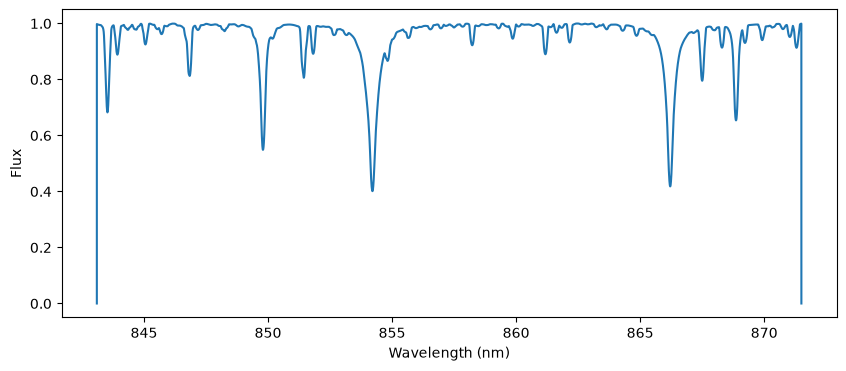

In [29]:
with fits.open('/Users/brooklyngustaf/Desktop/Research/NEID_Activity/synthetic_models/TIC_63939535/TIC_63939535_Teff4263_logg4.4_MH-0.08_vsini35.9_843.1_871.5.fits') as hdul:
    hdul.info()
    print(hdul[0].header)
    flux = hdul[0].data 
    header = hdul[0].header

    n = header["NAXIS1"]
    crval = header["CRVAL1"]
    cdelt = header["CDELT1"]
    crpix = header["CRPIX1"]

wave = crval + (np.arange(n) + 1 - crpix) * cdelt

plt.figure(figsize=(10,4))
plt.plot(wave, flux)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Flux")
plt.show()